In [61]:
import numpy as np
import os
import matplotlib.pyplot as plt
from generate_hmaps import height_map_pipeline
from PIL import Image
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from torchvision import io

In [62]:
# n1 = 256
# n2 = 32
# A = np.zeros((n1, n1))
# i = np.arange(0, n1, int(n1/n2))
# print(i)
# print(len(i))
# xi, yi = np.meshgrid(i, i)
# A[yi, xi] = 1
# # A[i,:]=1
# # A[:,i]=1
# print(A[yi, xi])
# plt.matshow(A)

# How to Store Height Map

In [63]:
path = 'mini_imagenet/n03676483/n03676483_18816.JPEG'
path = 'mini_imagenet/n02089867/n02089867_266.JPEG'
path = 'mini_imagenet/n01910747/n01910747_164.JPEG'
output_dir = "hmaps/test"
img_dir = path.split("/")[1]
# os.makedirs(os.path.join(output_dir, img_dir), exist_ok=True)
file = path.split("/")[-1].split(".")[0]
# output_path = os.path.join(output_dir, img_dir, f"{file}.npy")
jpeg95_path = os.path.join(output_dir, f"{file}_95.jpeg")
jpeg100_path = os.path.join(output_dir, f"{file}_100.jpeg")
png_path = os.path.join(output_dir, f"{file}.png")
# npy_path = os.path.join(output_dir, f"{file}.npy")


hmap = height_map_pipeline(path, device=device)
# np.save(npy_path, hmap)

# normalize height map to 0-255
ht = 0.07
h_min = -ht
h_max = ht
hmap_norm = (hmap - h_min)/(h_max - h_min) * 255

im = Image.fromarray(hmap_norm,)
im = im.convert("L") # convert image to greyscale
im.save(jpeg95_path, quality=95)
im.save(jpeg100_path, quality=100)
im.save(png_path, compress=0)

100%|██████████| 100/100 [00:00<00:00, 1180.01it/s]


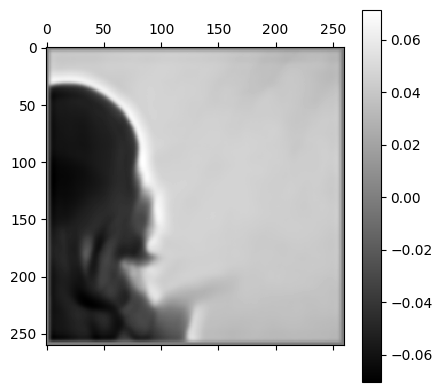

In [64]:
hmap_mat = plt.matshow(hmap, cmap='gray')
plt.colorbar(hmap_mat)
plt.show()

In [65]:
jpeg95 = io.decode_image(jpeg95_path, mode=io.ImageReadMode.GRAY)#Image.open(jpeg95_path)
h_jpeg95 = jpeg95/255 * (h_max - h_min) + h_min
h_jpeg95 = torch.squeeze(h_jpeg95)
# hmap_mat = plt.matshow(h_jpeg95, cmap='gray')
# plt.colorbar(hmap_mat)
# plt.show()

jpeg100 = io.decode_image(jpeg100_path, mode=io.ImageReadMode.GRAY)#Image.open(jpeg95_path)
h_jpeg100 = jpeg100/255 * (h_max - h_min) + h_min
h_jpeg100 = torch.squeeze(h_jpeg100)

png = io.decode_image(png_path, mode=io.ImageReadMode.GRAY)#Image.open(jpeg95_path)
h_png = png/255 * (h_max - h_min) + h_min
h_png = torch.squeeze(h_png)

# h_npy = np.load(npy_path)

In [66]:
# h_jpeg100 = h_jpeg95

Text(0.5, 1.0, 'PNG')

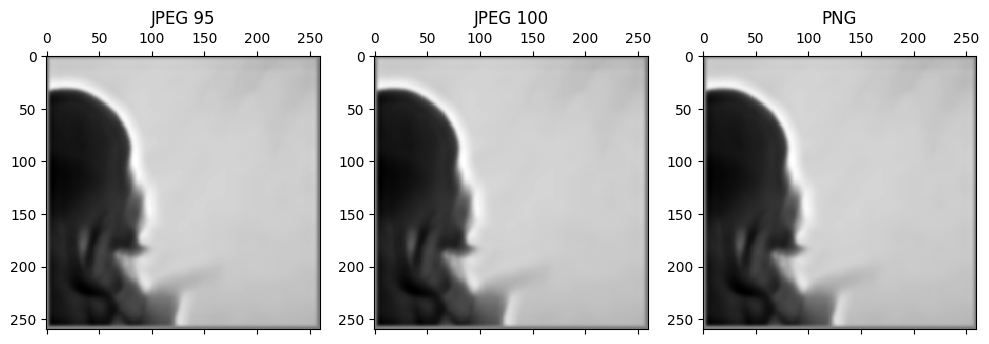

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].matshow(h_jpeg95, cmap='gray')
axes[0].set_title('JPEG 95')
axes[1].matshow(h_jpeg100, cmap='gray')
axes[1].set_title('JPEG 100')
axes[2].matshow(h_png, cmap='gray')
axes[2].set_title('PNG')

In [68]:
def abs_err(h_target, h2):
    return np.sum(np.abs(h_target - h2))
    # return np.mean(np.abs(h_target - h2)/(np.abs(h_target) + 1e-8))*100

def err_var(h_target, h2):
    return np.var(np.abs(h_target - h2))

In [69]:
jpeg95_abs_err = abs_err(hmap, h_jpeg95.numpy())
print("JPEG 95 Absolute Error:", jpeg95_abs_err)
jpeg100_abs_err = abs_err(hmap, h_jpeg100.numpy())
print("JPEG 100 Absolute Error:", jpeg100_abs_err)
png_abs_err = abs_err(hmap, h_png.numpy())
print("PNG Absolute Error:", png_abs_err)

print("-----------------------------------------------")

jpeg95_err_var = err_var(hmap, h_jpeg95.numpy())
print("JPEG 95 Error Variance:", jpeg95_err_var)
jpeg100_err_var = err_var(hmap, h_jpeg100.numpy())
print("JPEG 100 Error Variance:", jpeg100_err_var)
png_err_var = err_var(hmap, h_png.numpy())
print("PNG Error Variance:", png_err_var)

print("-----------------------------------------------")

jpeg95_max = np.max(np.abs(hmap-h_jpeg95.numpy()))
print("JPEG 95 Error Max:", jpeg95_max)
jpeg100_max = np.max(np.abs(hmap-h_jpeg100.numpy()))
print("JPEG 100 Error Max:", jpeg100_max)
png_max = np.max(np.abs(hmap-h_png.numpy()))
print("PNG Error Max:", png_max)


JPEG 95 Absolute Error: 19.959098663759157
JPEG 100 Absolute Error: 19.361423736423927
PNG Absolute Error: 18.49569896035193
-----------------------------------------------
JPEG 95 Error Variance: 3.7072292446758624e-08
JPEG 100 Error Variance: 3.1648140525184374e-08
PNG Error Variance: 2.4557407091893946e-08
-----------------------------------------------
JPEG 95 Error Max: 0.0018785519425758446
JPEG 100 Error Max: 0.001298227311603145
PNG Error Max: 0.001298227311603145


Text(0.5, 1.0, 'PNG Error')

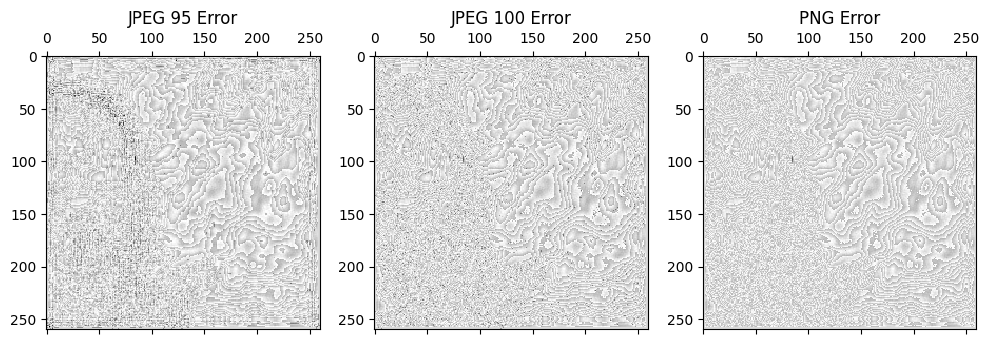

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
vmax = max(jpeg95_max, jpeg100_max, png_max)
axes[0].matshow(np.abs(hmap - h_jpeg95.numpy()), cmap='binary', vmax=vmax)
axes[0].set_title('JPEG 95 Error')
axes[1].matshow(np.abs(hmap - h_jpeg100.numpy()), cmap='binary', vmax=vmax)
axes[1].set_title('JPEG 100 Error')
axes[2].matshow(np.abs(hmap - h_png.numpy()), cmap='binary', vmax=vmax)
axes[2].set_title('PNG Error')